In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Find the project root
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIGURES_DIR = PROJECT_DIR / "results" / "figures"
TABLES_DIR = PROJECT_DIR / "results" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Processed data directory:", PROCESSED_DIR)

Project directory: c:\Users\ASUS\Documents\GitHub\Communication-Network-Failure-and-Resilience
Processed data directory: c:\Users\ASUS\Documents\GitHub\Communication-Network-Failure-and-Resilience\data\processed


In [2]:
edges = pd.read_csv(
    PROCESSED_DIR / "email_edges_clean.csv"
)

departments = pd.read_csv(
    PROCESSED_DIR / "email_departments_clean.csv"
)

print("Connections:", edges.shape)
print("Department labels:", departments.shape)

display(edges.head())
display(departments.head())

Connections: (25571, 2)
Department labels: (1005, 2)


,source,target
0,0,1
1,2,3
2,2,4
3,5,6
4,5,7


,node,department
0,0,1
1,1,1
2,2,21
3,3,21
4,4,21


In [3]:
# Directed graph: preserves the direction of email communication
G_directed = nx.DiGraph()

G_directed.add_edges_from(
    edges[["source", "target"]].itertuples(
        index=False, name=None
    )
)

# Include all nodes that have department labels
G_directed.add_nodes_from(departments["node"])

# Undirected graph: used for connectivity and resilience analysis
G_undirected = G_directed.to_undirected()

# Attach department information to each node
department_map = departments.set_index("node")["department"].to_dict()

nx.set_node_attributes(
    G_directed, department_map, "department"
)

nx.set_node_attributes(
    G_undirected, department_map, "department"
)

print("Directed graph created successfully!")
print("Undirected graph created successfully!")
print("Directed nodes:", G_directed.number_of_nodes())
print("Directed edges:", G_directed.number_of_edges())
print("Undirected edges:", G_undirected.number_of_edges())

Directed graph created successfully!
Undirected graph created successfully!
Directed nodes: 1005
Directed edges: 25571
Undirected edges: 16706


In [ ]:
n = G_directed.number_of_nodes()
m_directed = G_directed.number_of_edges()
m_undirected = G_undirected.number_of_edges()

in_degree = dict(G_directed.in_degree())
out_degree = dict(G_directed.out_degree())
degree = dict(G_undirected.degree())

components = list(nx.connected_components(G_undirected))

component_sizes = sorted(
    [len(component) for component in components],
    reverse=True
)

largest_component = component_sizes[0] if component_sizes else 0

graph_stats = pd.DataFrame({
    "Metric": [
        "Number of nodes",
        "Directed edges",
        "Undirected edges",
        "Directed graph density",
        "Undirected graph density",
        "Average in-degree",
        "Average out-degree",
        "Average undirected degree",
        "Number of connected components",
        "Largest connected component size",
        "Largest component percentage",
        "Number of departments"
    ],
    "Value": [
        n,
        m_directed,
        m_undirected,
        nx.density(G_directed),
        nx.density(G_undirected),
        np.mean(list(in_degree.values())),
        np.mean(list(out_degree.values())),
        np.mean(list(degree.values())),
        len(components),
        largest_component,
        (largest_component / n * 100) if n else 0,
        departments["department"].nunique()
    ]
})

display(graph_stats)

graph_stats.to_csv(
    TABLES_DIR / "graph_basic_statistics.csv",
    index=False
)

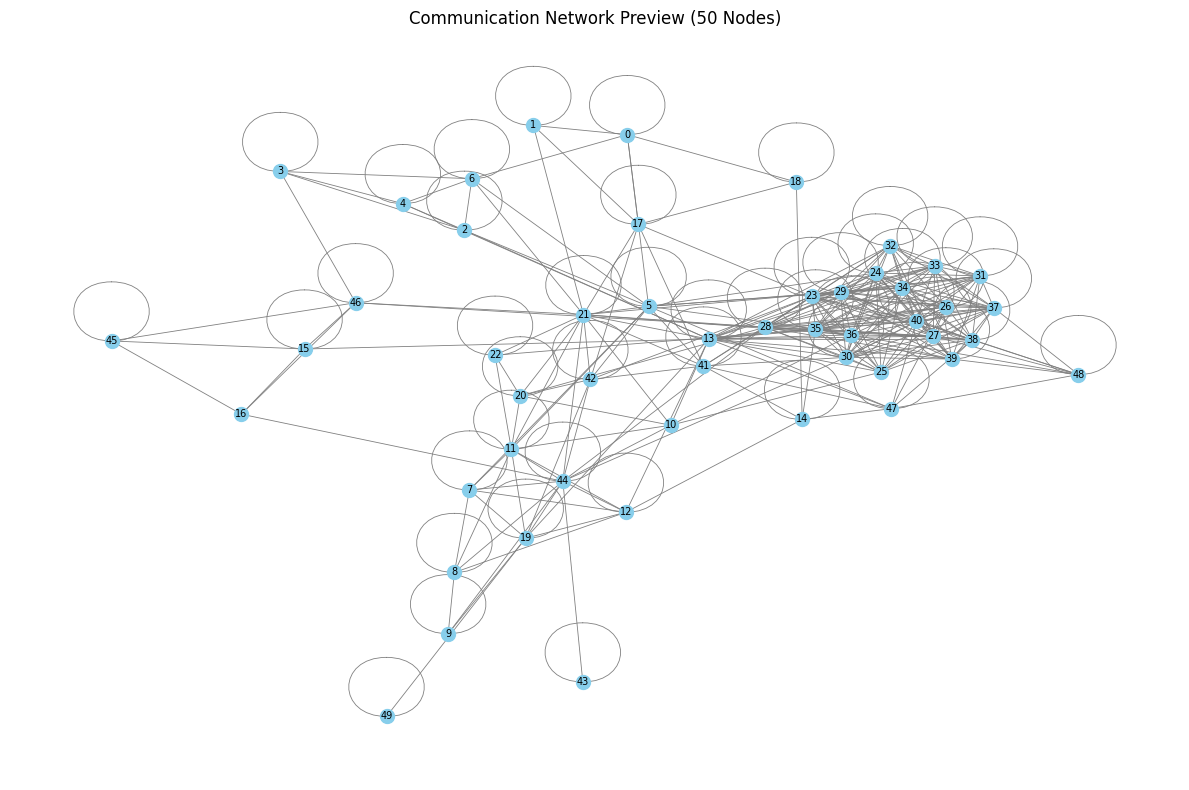

In [4]:
import matplotlib.pyplot as plt
import networkx as nx

# Select a small subgraph for a readable preview
sample_nodes = list(G_undirected.nodes())[:50]
G_sample = G_undirected.subgraph(sample_nodes).copy()

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G_sample, seed=42)

nx.draw_networkx(
    G_sample,
    pos=pos,
    node_size=100,
    node_color="skyblue",
    edge_color="gray",
    font_size=7,
    with_labels=True,
    width=0.6
)

plt.title("Communication Network Preview (50 Nodes)")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "communication_network_preview.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()